In [1]:
import numpy as np
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
import matplotlib.pyplot as plt

## Coordenadas

In [2]:
coords = np.load("coords_CA.npy")
nombres = [l.strip() for l in open("coords_nombres.csv")]

In [3]:
type(coords) 
#dimension
coords.shape

(100, 12, 3)

In [4]:
N = coords.shape[0]
rmsd_matrix = np.zeros((N, N))

for i in range(N):
    d = coords[i] - coords  
    
    rmsd_matrix[i] = np.sqrt((d ** 2).sum(axis=2).mean(axis=1))

print("Matriz RMSD:", rmsd_matrix.shape)

Matriz RMSD: (100, 100)


## RMSD

In [5]:
rmsd = np.load("rmsd_matrix.npy")
nombres = [l.strip() for l in open("rmsd_nombres.csv")]

In [6]:
rmsd_matrix==rmsd

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True]], shape=(100, 100))

In [7]:
rmsd

array([[ 0.        ,  0.87091756,  5.70518923, ..., 10.84222698,
         5.49158716, 10.81240654],
       [ 0.87091756,  0.        ,  6.11269855, ..., 10.94864273,
         6.07586288, 10.89350128],
       [ 5.70518923,  6.11269855,  0.        , ..., 10.26109886,
         4.15069532, 10.35873985],
       ...,
       [10.84222698, 10.94864273, 10.26109886, ...,  0.        ,
        10.23989773,  0.66419417],
       [ 5.49158716,  6.07586288,  4.15069532, ..., 10.23989773,
         0.        , 10.35904884],
       [10.81240654, 10.89350128, 10.35873985, ...,  0.66419417,
        10.35904884,  0.        ]], shape=(100, 100))

In [8]:
dist = squareform(rmsd, checks=False) # Como es una matriz simetrica, se convierte a un vector

In [9]:
rmsd

array([[ 0.        ,  0.87091756,  5.70518923, ..., 10.84222698,
         5.49158716, 10.81240654],
       [ 0.87091756,  0.        ,  6.11269855, ..., 10.94864273,
         6.07586288, 10.89350128],
       [ 5.70518923,  6.11269855,  0.        , ..., 10.26109886,
         4.15069532, 10.35873985],
       ...,
       [10.84222698, 10.94864273, 10.26109886, ...,  0.        ,
        10.23989773,  0.66419417],
       [ 5.49158716,  6.07586288,  4.15069532, ..., 10.23989773,
         0.        , 10.35904884],
       [10.81240654, 10.89350128, 10.35873985, ...,  0.66419417,
        10.35904884,  0.        ]], shape=(100, 100))

In [10]:
dist # Van primero las distancias de la primera fila, luego las de la segunda y así, la diagonal no se incluye.

array([ 0.87091756,  5.70518923, 10.8539753 , ..., 10.23989773,
        0.66419417, 10.35904884], shape=(4950,))

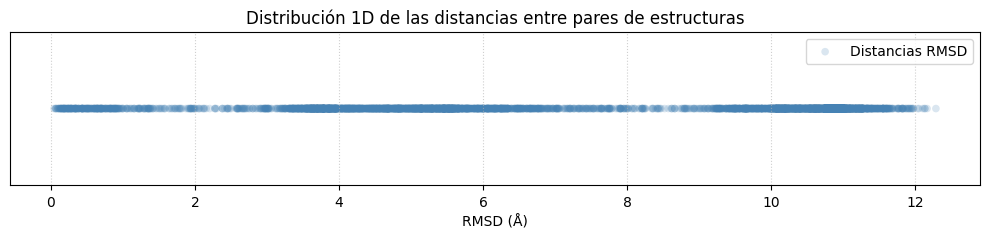

In [11]:
# Gráfico 1D de la distribución de distancias RMSD
plt.figure(figsize=(10, 2.5))

# 1. Puntos de distancia RMSD (Eje Y = 0 para simular 1D)
plt.scatter(
    dist, 
    np.zeros_like(dist), 
    alpha=0.2,            # Transparencia para ver dónde se solapan los puntos
    color='steelblue', 
    edgecolor='none', 
    s=30, 
    label='Distancias RMSD'
)

plt.xlabel("RMSD (Å)")
plt.yticks([])  # Oculta el eje Y ya que no aporta información
plt.title("Distribución 1D de las distancias entre pares de estructuras")
plt.legend(loc="upper right")
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()

plt.show()

## Clustering jerárquico

In [12]:
# distancia minima
single = linkage(dist, method="single")

# distancia máxima
complete = linkage(dist, method="complete")

# distancia promedio
average = linkage(dist, method="average")

In [23]:
def dendrograma(metodo_enlace, distancia_corte):

    plt.figure(figsize=(14, 5))
    dendrogram(metodo_enlace, labels=nombres, leaf_rotation=90, leaf_font_size=6, color_threshold=distancia_corte)

    plt.axhline(
        y=distancia_corte,
        color="r",
        linestyle="--",
        linewidth=1.5,
        label=f"Corte ({distancia_corte} Å)",
    )

    plt.ylabel("RMSD (Å)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    # Corte por distancia 
    CORTE = distancia_corte  # Å
    clusters = fcluster(metodo_enlace, t=CORTE, criterion="distance")
    print("Número de clusters:", clusters.max())

    # Representante: el de menor RMSD promedio a los demás de su cluster
    representantes = {}
    for c in np.unique(clusters):
        idx = np.where(clusters == c)[0]
        if len(idx) == 1: # Si el cluster contiene un solo elemento, no hay nada que calcular
            rep = idx[0]
        else:
            sub = rmsd[np.ix_(idx, idx)] # Extrae una submatriz que contiene solo las distancias entre las estructuras de este cluster.
            rep = idx[sub.mean(axis=1).argmin()] # Calcula el promedio de RMSD de cada elemento respecto a todos los demás elementos del mismo cluster.
            # Encuentra la posición del elemento que tiene la menor distancia promedio hacia sus compañeros
        representantes[c] = (nombres[rep], len(idx))



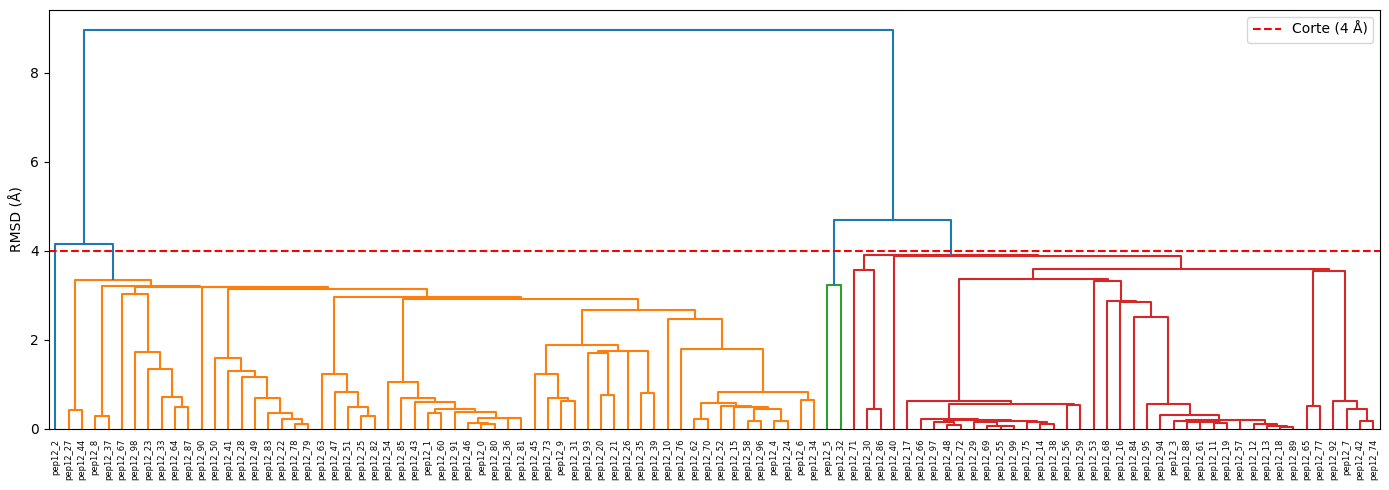

Número de clusters: 4


In [33]:
dendrograma(single, 4)

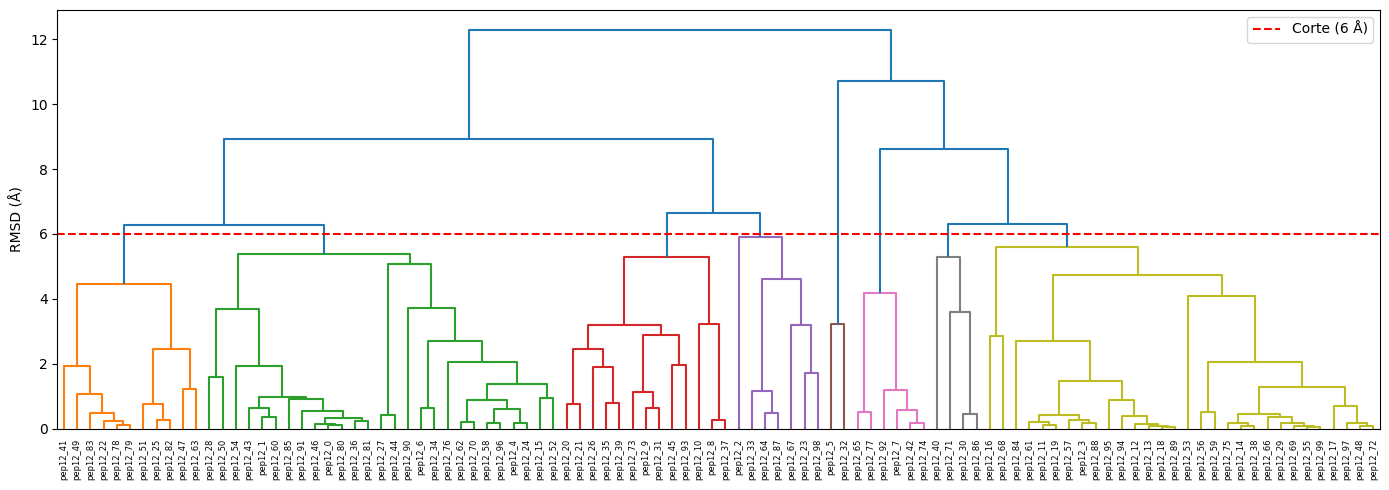

Número de clusters: 8


In [29]:
dendrograma(complete,6)

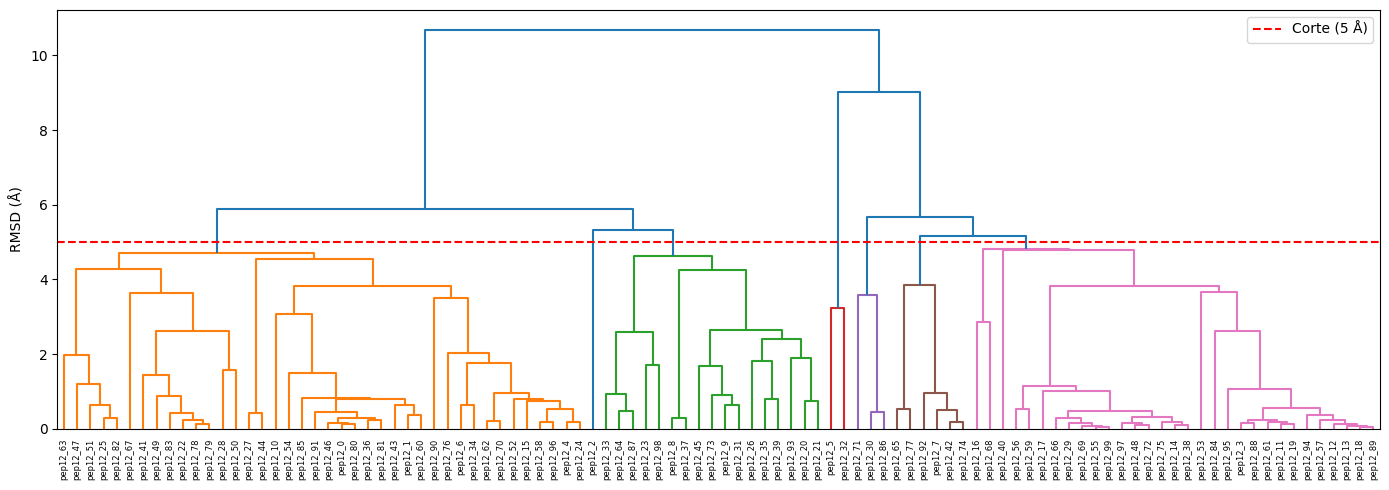

Número de clusters: 7


In [34]:
dendrograma(average,5)

Complete se puede ver como que "en el peor de los casos están a distancia..." y single que en el mejor.
El que parece ser el mejor método es el complete, pero probaremos con vecinos más cercanos.

## K means

Matriz para k-means: (100, 36)


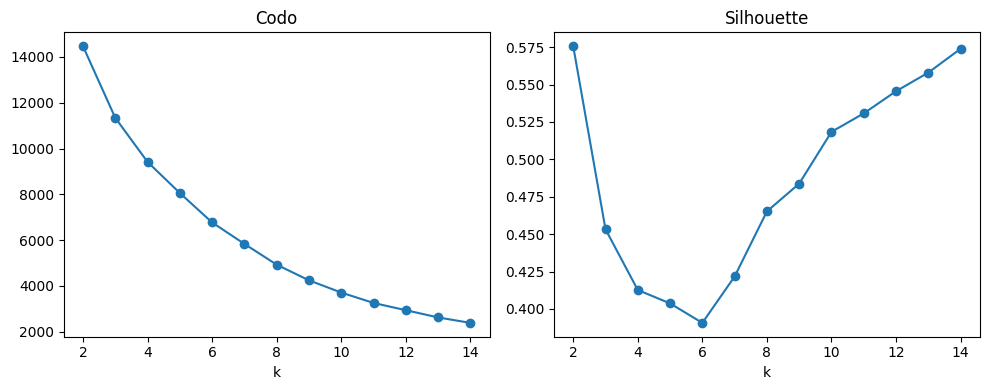

k elegido por Silhouette: 2 | tamaños: [58 42]


In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


X = coords.reshape(len(coords), -1)                    
print("Matriz para k-means:", X.shape) # aplanamos las coordenadas para que el algoritmo lo lea

# Probar varios k
ks = range(2, 15)
inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(X)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(list(ks), inercia, marker="o"); ax[0].set_title("Codo"); ax[0].set_xlabel("k")
ax[1].plot(list(ks), sil, marker="o");     ax[1].set_title("Silhouette");      ax[1].set_xlabel("k")
plt.tight_layout(); plt.savefig("kmeans_k.png", dpi=200); plt.show()

K = int(list(ks)[int(np.argmax(sil))])
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(X)
etiq = km.labels_
print("k elegido por Silhouette:", K, "| tamaños:", np.bincount(etiq))


A partir de dos vuelve a subir, pero observamos que ni hasta 15 llega a k=2 por el método siluette.
En el codo no se logra identificar una pendiente marcada.
Número de grupos podría ser 8 porque es cuando supera el bajon del k=3 en siluette

In [64]:
K = 8
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(X)
etiq = km.labels_

print("k elegido:", K, "| tamaños por cluster:", np.bincount(etiq))

reps = []
for c in range(K):
    idx = np.where(etiq == c)[0]
    # Distancia euclidiana de cada punto del cluster 'c' a su centroide
    d = np.linalg.norm(X[idx] - km.cluster_centers_[c], axis=1)
    # Selecciona el índice del diseño con la distancia mínima (medoide/representante)
    reps.append(idx[d.argmin()])

print("\n--- REPRESENTANTES PARA K = 8 ---")
for c, r_idx in enumerate(reps):
    print(f"Cluster {c} (n={np.sum(etiq == c)}): {nombres[r_idx]}")

# ==============================================================================
# 6) Evaluación: RMSD real (Å) de cada diseño a su representante
# ==============================================================================
intra = [rmsd[i, reps[etiq[i]]] for i in range(len(etiq))]
print(f"\nRMSD medio al representante: {np.round(np.mean(intra), 2)} Å")
print(f"RMSD máximo al representante: {np.round(np.max(intra), 2)} Å")


k elegido: 8 | tamaños por cluster: [ 6 11 12 15 16  5 16 19]

--- REPRESENTANTES PARA K = 8 ---
Cluster 0 (n=6): pep12_92
Cluster 1 (n=11): pep12_49
Cluster 2 (n=12): pep12_85
Cluster 3 (n=15): pep12_38
Cluster 4 (n=16): pep12_3
Cluster 5 (n=5): pep12_86
Cluster 6 (n=16): pep12_9
Cluster 7 (n=19): pep12_15

RMSD medio al representante: 1.68 Å
RMSD máximo al representante: 6.61 Å


Se decide utilizar el clustering jerarquico con el método de enlace complete, ya que de esa forma nos aseguramos que en el peor caso están a distancia de 6A

In [ ]:
def dendrograma(metodo_enlace, distancia_corte):

    plt.figure(figsize=(14, 5))
    dendrogram(metodo_enlace, labels=nombres, leaf_rotation=90, leaf_font_size=6, color_threshold=distancia_corte)

    plt.axhline(
        y=distancia_corte,
        color="r",
        linestyle="--",
        linewidth=1.5,
        label=f"Corte ({distancia_corte} Å)",
    )

    plt.ylabel("RMSD (Å)")
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

    # Corte por distancia 
    CORTE = distancia_corte  # Å
    clusters = fcluster(metodo_enlace, t=CORTE, criterion="distance")
    print("Número de clusters:", clusters.max())

    # Representante: el de menor RMSD promedio a los demás de su cluster
    representantes = {}
    for c in np.unique(clusters):
        idx = np.where(clusters == c)[0]
        if len(idx) == 1: # Si el cluster contiene un solo elemento, no hay nada que calcular
            rep = idx[0]
        else:
            sub = rmsd[np.ix_(idx, idx)] # Extrae una submatriz que contiene solo las distancias entre las estructuras de este cluster.
            rep = idx[sub.mean(axis=1).argmin()] # Calcula el promedio de RMSD de cada elemento respecto a todos los demás elementos del mismo cluster.
            # Encuentra la posición del elemento que tiene la menor distancia promedio hacia sus compañeros
        representantes[c] = (nombres[rep], len(idx))

